# Demo 1: Attack and Defence

A universal adversarial snippet (0.64s, L∞ ≤ 0.005) is prepended to speech so that Whisper emits end-of-transcript (eot) immediately (*complete suppression*) or within a few tokens (*partial suppression*).

This notebook loads snippets from `outputs/snippets/`, but if no saved snippet exists, a quick (weak) one is trained.

In [8]:
%load_ext autoreload
%autoreload 2

import torch
from torch.utils.data import DataLoader

from asrvuln import config, data, models, audio, prepare, attack, evaluate, defences, viz

device = models.get_device()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device: cuda


## 1. Model and Data

In [ ]:
MODEL_NAME = "tiny.en"          # the model the snippets were trained on
CLAMP_EP = config.DEFAULT_CLAMP_EP
TEST_N = 50                      # our paper used 250, we use 50 here for toy example

model = models.load_whisper(MODEL_NAME, device)
test = data.load_tedlium("test", n=TEST_N, seed=1)

## 2. Adversarial Snippet

In [10]:
SNIPPET_PATH = config.SNIPPETS_DIR / "complete_snippets.pt"   # set partial or complete snippet here

# success tracking collected in this session, {(mode, split): (ids, lengths)}; used by section 6
tracked = {}

if SNIPPET_PATH.exists():
    snippets = torch.load(SNIPPET_PATH, weights_only=True)
    snippet = snippets[-1].unsqueeze(0)
else:
    print(f"{SNIPPET_PATH} not found - training a quick, weak snippet instead (with success tracking)")
    train_dl = DataLoader(data.load_tedlium("train", n=20, seed=1, with_idx=True), collate_fn=data.collate_idx)
    valid_dl = DataLoader(data.load_tedlium("validation", n=10, seed=1, with_idx=True), collate_fn=data.collate_idx)
    snippet, _, train_success, valid_success = attack.train(model, attack.forward, train_dl, valid_dl,
                                                            prepare.PrepareAtPosition(config.DEFAULT_SNIPPET_SIZE, 0),
                                                            train_success={}, valid_success={},
                                                            iter_limit=4, patience=3, clamp_epsilon=CLAMP_EP)
    for split, success in (("train", train_success), ("valid", valid_success)):
        if success:
            tracked[("complete", split)] = attack.success_to_tensor(success)

method = prepare.PrepareFront(tuple(snippet.shape))
snippet.shape, snippet.abs().max().item()

(torch.Size([1, 10240]), 0.004999999888241291)

## 3. Sanity Check

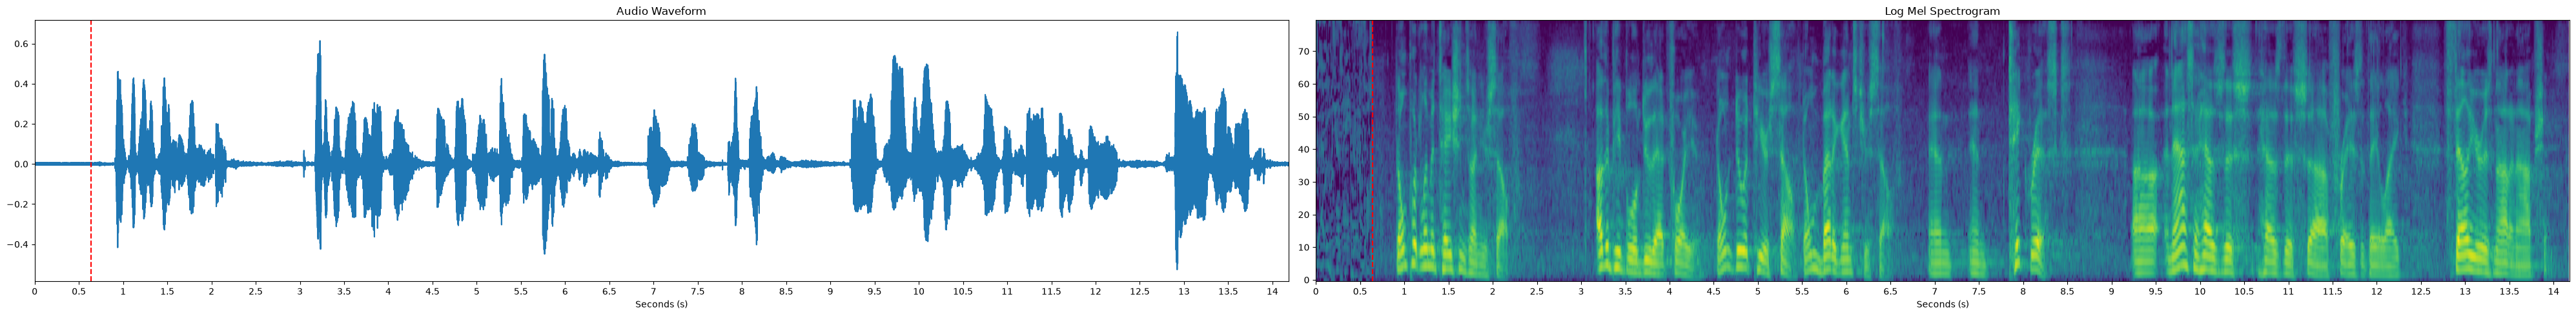

In [11]:
example = test[2]["audio"]
attacked = method(snippet, example.unsqueeze(0)).squeeze(0)

viz.plot_waveform_and_mel(attacked, snippet_len=snippet.size(1))
audio.play_audio(example)
audio.play_audio(attacked)

In [12]:
fp16 = device == "cuda"
for name, wave in {"clean": example, "attacked": attacked}.items():
    text = model.transcribe(wave.to(device), language="en", condition_on_previous_text=False, fp16=fp16)["text"]
    print(f"{name:>9}: {text!r}")

    clean: " Don't put limitations on yourself. Other people will do that for you. Don't do it to yourself. Don't bet against yourself. And take risks. NASA has this phrase that they like, failure is not an option."
 attacked: ''


## 4. Evaluation

In [13]:
results = {}
results["attack (complete)"] = evaluate.evaluate(model, snippet, method, test, CLAMP_EP)

random_snippet = (torch.rand(snippet.shape) * 2 - 1) * CLAMP_EP
results["random noise"] = evaluate.evaluate(model, random_snippet, method, test, CLAMP_EP)

results["no snippet"] = evaluate.evaluate(model, torch.empty(1, 0), method, test, CLAMP_EP)

Clamp: 0.005
Prepare Method: prepare_front
Snippet Size: (1, 10240)
Position: 0


Inference: 100%|██████████| 50/50 [00:04<00:00, 12.46it/s, Valid Examples: 36 | Non-empty ASL: Undefined]




Total valid examples: 36
Success rate (Empty): 1.0
Success rate (ASL): 0.0 (attacked) out of 121.02777777777777 (original)
Average Bleu Score: 0.0
Average WER: 1.0
Average SNR (dB): 38.162083572811554
Average STOI: 0.9999850497237092
Clamp: 0.005
Prepare Method: prepare_front
Snippet Size: (1, 10240)
Position: 0


Inference: 100%|██████████| 50/50 [00:19<00:00,  2.56it/s, Valid Examples: 36 | Non-empty ASL: 121.97222222222223]




Total valid examples: 36
Success rate (Empty): 0.0
Success rate (ASL): 121.97222222222223 (attacked) out of 121.02777777777777 (original)
Average Bleu Score: 0.6287931799888611
Average WER: 0.37489197425351295
Average SNR (dB): 39.56962850358751
Average STOI: 0.9999925010225075
Clamp: 0.005
Prepare Method: prepare_front
Snippet Size: (1, 10240)
Position: 0


Inference: 100%|██████████| 50/50 [00:19<00:00,  2.55it/s, Valid Examples: 36 | Non-empty ASL: 121.41666666666667]



Total valid examples: 36
Success rate (Empty): 0.0
Success rate (ASL): 121.41666666666667 (attacked) out of 121.02777777777777 (original)
Average Bleu Score: 0.6336168050765991
Average WER: 0.3660651592623329
Average SNR (dB): 98.14832178751628
Average STOI: 0.9999999999999998


In [14]:
PARTIAL_PATH = config.SNIPPETS_DIR / "partial_snippets.pt"     # scripts/train_attack.py --mode partial
if PARTIAL_PATH.exists():
    partial = torch.load(PARTIAL_PATH, weights_only=True)[-1].unsqueeze(0)
    results["attack (partial)"] = evaluate.evaluate(model, partial, prepare.PrepareFront(tuple(partial.shape)), test, CLAMP_EP)
else:
    print(f"{PARTIAL_PATH} not found - skipping partial suppression")

Clamp: 0.005
Prepare Method: prepare_front
Snippet Size: (1, 10240)
Position: 0


Inference: 100%|██████████| 50/50 [00:21<00:00,  2.28it/s, Valid Examples: 36 | Non-empty ASL: 116.36111111111111]



Total valid examples: 36
Success rate (Empty): 0.0
Success rate (ASL): 116.36111111111111 (attacked) out of 121.02777777777777 (original)
Average Bleu Score: 0.579446017742157
Average WER: 0.4306384825511723
Average SNR (dB): 37.90721548928155
Average STOI: 0.9999856937697307


## 5. Defences

In [ ]:
defenders = {
    "lowpass 7.5 kHz": defences.PrepareFrontLowpass(tuple(snippet.shape), cutoff=7500),
    "mu-law": defences.PrepareFrontMu(tuple(snippet.shape)),
}
for name, defender in defenders.items():
    results[f"attack + {name}"] = evaluate.evaluate(model, snippet, defender, test, CLAMP_EP, verbose=False)
    results[f"clean + {name}"] = evaluate.evaluate(model, torch.empty(1, 0), defender, test, CLAMP_EP, verbose=False)

Inference: 100%|██████████| 50/50 [00:19<00:00,  2.51it/s, Valid Examples: 36 | Non-empty ASL: 121.41666666666667]

                            empty_rate         asl        bleu         wer      snr_db        stoi
attack (complete)               1.0000      0.0000      0.0000      1.0000     38.1621      1.0000
random noise                    0.0000    121.9722      0.6288      0.3749     39.5696      1.0000
no snippet                      0.0000    121.4167      0.6336      0.3661     98.1483      1.0000
attack (partial)                0.0000    116.3611      0.5794      0.4306     37.9072      1.0000
attack + lowpass 7.5 kHz        0.7500     24.5556      0.1552      0.8443     38.2826      1.0000
clean + lowpass 7.5 kHz         0.0000    121.6111      0.6350      0.3648     98.1472      1.0000
attack + mu-law                 1.0000      0.0000      0.0000      1.0000     38.1621      1.0000
clean + mu-law                  0.0000    121.4167      0.6336      0.3661     98.1483      1.0000


## 6. Results
Metrics: 
* Empty-transcription rate
* Average sequence length (characters)
* Unigram BLEU
* Word Error Rate (WER)s two
* SNR in dB (higher = quieter perturbation)
* STOI in [0, 1] (higher = more intelligible speech).

In [17]:
evaluate.summarise(results)

                            empty_rate         asl        bleu         wer      snr_db        stoi
attack (complete)               1.0000      0.0000      0.0000      1.0000     38.1621      1.0000
random noise                    0.0000    121.9722      0.6288      0.3749     39.5696      1.0000
no snippet                      0.0000    121.4167      0.6336      0.3661     98.1483      1.0000
attack (partial)                0.0000    116.3611      0.5794      0.4306     37.9072      1.0000
attack + lowpass 7.5 kHz        0.7500     24.5556      0.1552      0.8443     38.2826      1.0000
clean + lowpass 7.5 kHz         0.0000    121.6111      0.6350      0.3648     98.1472      1.0000
attack + mu-law                 1.0000      0.0000      0.0000      1.0000     38.1621      1.0000
clean + mu-law                  0.0000    121.4167      0.6336      0.3661     98.1483      1.0000


## 7. Example Suppression Tracking

Track which example was suppressed and which was not: transcript length per validation example (rows) per training iteration (columns).

Requires success tracking, saved by:
* Declaring `scripts/train_attack.py --mode <mode> --track-success valid` (or `all`) 
* Pasting known results to `outputs/tensors/<mode>_valid_success.pt` and `<mode>_valid_ids.pt`. 
* Passing `attack.train(..., train_success={}, valid_success={})` in this notebook (in 2. Adversarial Snippet) and convert the returned dicts with `attack.success_to_tensor`.

In [16]:
# Tracking from the quick snippet trained in section 2 (this session) comes first, since it matches the
# snippet in use; otherwise load what scripts/train_attack.py --track-success saved. One heatmap per (mode, split).
for mode in ("complete", "partial"):
    for split in ("train", "valid"):
        success_path = config.TENSORS_DIR / f"{mode}_{split}_success.pt"
        ids_path = config.TENSORS_DIR / f"{mode}_{split}_ids.pt"
        if (mode, split) in tracked:
            ids, lengths = tracked[(mode, split)]
            source = "quick snippet trained in section 2"
        elif success_path.exists():
            ids, lengths = torch.load(ids_path, weights_only=True), torch.load(success_path, weights_only=True)
            source = success_path
        else:
            continue
        print(f"{mode} suppression, {split} set ({source})")
        viz.plot_success_heatmap(lengths, ids.tolist())

if not tracked and not any(config.TENSORS_DIR.glob("*_success.pt")):
    print(f"No success tracking found in {config.TENSORS_DIR} - run scripts/train_attack.py with --track-success")

No success tracking found in C:\Coding\asr\outputs\tensors - run scripts/train_attack.py with --track-success
